# Bid-ask spread from OHLC prices: EDGE

Research seminar, module 2. Paper: Ardia, Guidotti, Kroencke, *Efficient estimation of bid-ask spreads from open, high, low, and close prices*, JFE 2024.

Everything below is computed in this notebook: the estimator is checked against the authors' package and test vectors, the simulations of the paper are rerun at a smaller scale, the real-data examples use the extracts in `data/sample/`, and the benchmarks are recomputed from the per-day tables in `results/`, which the scripts in `scripts/` built from 25 GB of Binance trades and quotes and from our own Moscow Exchange quote feed. Runs in Google Colab (the first cell clones the repository) or locally from the repository root; a few minutes on two cores.

In [1]:
import importlib, importlib.util, os, subprocess, sys
REPO = 'https://github.com/d9nk/edge-spread-project.git'
in_colab = importlib.util.find_spec('google.colab') is not None
if not os.path.exists('src/edgespread'):
    subprocess.run(['git', 'clone', '-q', REPO], check=True)
    os.chdir('edge-spread-project')
elif in_colab and os.path.isdir('.git'):
    subprocess.run(['git', 'fetch', '-q', 'origin', 'main'], check=True)
    subprocess.run(['git', 'reset', '-q', '--hard', 'origin/main'], check=True)
for name in [m for m in sys.modules if m == 'edgespread' or m.startswith('edgespread.')]:
    del sys.modules[name]
importlib.invalidate_caches()
for package, module in (('bidask==2.1.0', 'bidask'), ('pytest', 'pytest')):
    if importlib.util.find_spec(module) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', package], check=True)
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from dataclasses import replace
def sample(name):
    path = os.path.join('data', 'sample', name)
    if not os.path.exists(path):
        import requests
        os.makedirs(os.path.dirname(path), exist_ok=True)
        r = requests.get(f'https://raw.githubusercontent.com/d9nk/edge-spread-project/main/data/sample/{name}', timeout=60)
        r.raise_for_status()
        open(path, 'wb').write(r.content)
    return path
sys.path.insert(0, 'src')
from edgespread import SimConfig, simulate, estimate, edge, clip_zero, windows_with_lag
pd.set_option('display.width', 200)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3, 'axes.spines.top': False, 'axes.spines.right': False, 'legend.frameon': False})

## 1. The estimator

Written from Table 1 and equations (7)-(25) of the paper: the four corrected building blocks, the two moment conditions and the inverse-variance weights. This is the core function; `estimate()` wraps it together with Roll, Corwin-Schultz and Abdi-Ranaldo and accepts one series or a batch of them.

In [2]:
import inspect
from edgespread import estimators
print(inspect.getsource(estimators.edge_components))

def edge_components(open, high, low, close) -> dict[str, np.ndarray]:
    (o, h, l, c), _ = _log_prices(open, high, low, close)
    eta = (h + l) / 2.0

    h1, l1, c1, eta1 = h[:, :-1], l[:, :-1], c[:, :-1], eta[:, :-1]
    o, h, l, eta = o[:, 1:], h[:, 1:], l[:, 1:], eta[:, 1:]

    tau = _indicator((h != l) | (l != c1), h, l, c1)
    phi_oh = _indicator(o != h, o, h) * tau
    phi_ol = _indicator(o != l, o, l) * tau
    phi_ch = _indicator(c1 != h1, c1, h1) * tau
    phi_cl = _indicator(c1 != l1, c1, l1) * tau

    p_tau = _nanmean(tau)
    n_tau = np.nansum(tau, axis=1)
    p_o = _nanmean(phi_oh) + _nanmean(phi_ol)
    p_c = _nanmean(phi_ch) + _nanmean(phi_cl)

    with np.errstate(divide="ignore", invalid="ignore"):
        pi_o = -8.0 / p_o
        pi_c = -8.0 / p_c

    r_eo = eta - o
    r_oe = o - eta1
    r_ec = eta - c1
    r_ce = c1 - eta1
    r_oc = o - c1

    def demean(r: np.ndarray) -> np.ndarray:
        with np.errstate(divide="ignore", invalid="ignore"):
           

The authors publish three test values with their package and a 10,000-day test file. Our implementation returns the same numbers and agrees with the package on simulated prices with missing values.

In [3]:
import requests
from bidask import edge as bidask_edge
os.makedirs('data/authors', exist_ok=True)
for name in ('ohlc', 'ohlc-miss'):
    path = f'data/authors/bidask_{name}.csv'
    if not os.path.exists(path):
        open(path, 'wb').write(requests.get(f'https://raw.githubusercontent.com/eguidotti/bidask/main/pseudocode/{name}.csv', timeout=60).content)
full = pd.read_csv('data/authors/bidask_ohlc.csv')
miss = pd.read_csv('data/authors/bidask_ohlc-miss.csv')
checks = pd.DataFrame([
    ('10,000 days', edge(full.Open, full.High, full.Low, full.Close), 0.0101849034905478),
    ('first 10 days, signed', edge(full.Open[:10], full.High[:10], full.Low[:10], full.Close[:10], sign=True), -0.016889917516422),
    ('10,000 days with missing values', edge(miss.Open, miss.High, miss.Low, miss.Close), 0.01013284969780197),
], columns=["authors' test case", 'ours', 'published value'])
checks['difference'] = (checks['ours'] - checks['published value']).abs()
display(checks)
rng = np.random.default_rng(1)
o, h, l, c = (x.copy() for x in simulate(500, SimConfig(prob=0.05, spread=0.02), rng).T)
for x in (o, h, l, c):
    x[rng.random(500) < 0.05] = np.nan
print('simulated prices with 5 % missing values:  ours', edge(o, h, l, c, sign=True), '  bidask', bidask_edge(o, h, l, c, True))

,authors' test case,ours,published value,difference
0,"10,000 days",0.010185,0.010185,3.816392e-17
1,"first 10 days, signed",-0.016890,-0.016890,3.469447e-17
2,"10,000 days with missing values",0.010133,0.010133,3.469447e-18


simulated prices with 5 % missing values:  ours 0.01946437087913488   bidask 0.019464370879134885


The test suite: the test vectors, agreement with the package, the formulas of the other estimators, the simulator, bar construction, the benchmark functions and the data readers.

In [4]:
r = subprocess.run([sys.executable, '-m', 'pytest', '-q', '--color=no', 'tests'], capture_output=True, text=True)
print(r.stdout.strip().splitlines()[-1])

67 passed in 1.04s


## 2. The simulations of the paper, rerun

Section 4.1 of the paper: a random walk with 390 potential trades a day, 3 % daily volatility, each trade at the bid or the ask with probability 1/2, observed with probability `prob`; an empty period carries the previous close. The full runs (10,000 months per cell, `scripts/run_simulations.py`, 13 s on 14 cores) are in `results/sim/`; here the same code at a scale that fits a notebook.

**Fig. 2.** True spread 1 %, one path of 20,000 days per point. CS collapses below about 13 trades a day, AR loses most of the spread at one trade a day, EDGE stays at 1 %.

,EDGE,AR,CS
trades per day,,,
1.000000,1.079,0.296,0.000
2.345050,0.992,0.590,0.000
5.499259,0.971,0.800,0.000
12.896037,1.022,0.934,0.000
30.241849,1.022,1.020,0.297
70.918646,0.972,0.905,0.566
166.307762,0.991,0.933,0.819
390.000000,1.014,1.050,1.031


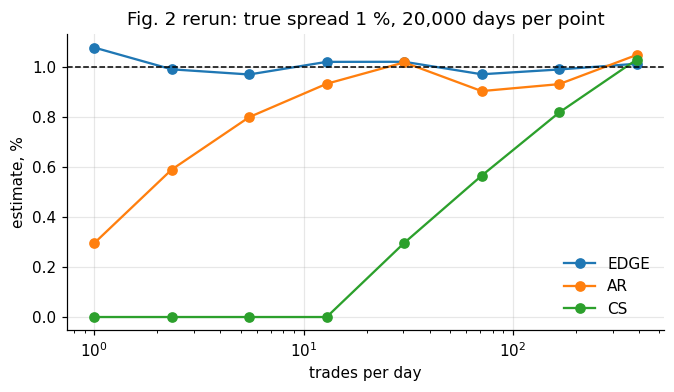

In [5]:
rows = []
for p in np.exp(np.linspace(np.log(1 / 390), 0.0, 8)):
    o, h, l, c = simulate(20_000, SimConfig(prob=float(p), spread=0.01), np.random.default_rng(int(1e6 * p))).T
    e = estimate(o, h, l, c, methods=('EDGE', 'AR', 'CS'), sign=True)
    rows.append({'trades per day': 390 * p, **{k: 100 * clip_zero(v) for k, v in e.items()}})
fig2 = pd.DataFrame(rows).set_index('trades per day')
ax = fig2.plot(logx=True, marker='o', figsize=(7, 3.5), ylabel='estimate, %', title='Fig. 2 rerun: true spread 1 %, 20,000 days per point')
ax.axhline(1.0, color='black', linestyle='--', linewidth=1)
fig2.round(3)

**Table 2.** Mean of 2,000 monthly estimates, negatives reset to zero, in %: ours / the paper's Table 2. Panel A: every trade observed; Panel B: 1 % of trades, 3.9 a day.

In [6]:
paper = {'A': {'EDGE': [0.44, 0.90, 2.88], 'AR': [0.70, 0.95, 2.92], 'CS': [0.60, 1.03, 2.95], 'ROLL': [1.44, 1.59, 2.95]},
         'B': {'EDGE': [0.71, 0.95, 2.89], 'AR': [0.65, 0.81, 2.26], 'CS': [0.02, 0.04, 0.35], 'ROLL': [1.44, 1.56, 2.89]}}
rows = []
for panel, prob in (('A', 1.0), ('B', 0.01)):
    for i, spread in enumerate((0.005, 0.01, 0.03)):
        bars = simulate(2000 * 21, SimConfig(prob=prob, spread=spread), np.random.default_rng(int(1000 * spread) + int(10 * prob)))
        o, h, l, c = windows_with_lag(bars, 21)
        e = estimate(o, h, l, c, methods=('EDGE', 'AR', 'CS', 'ROLL'), sign=True)
        rows.append({'panel': panel, 'true spread': f'{100 * spread:.1f}%', **{m: f'{100 * np.nanmean(clip_zero(v)):.2f} / {paper[panel][m][i]:.2f}' for m, v in e.items()}})
pd.DataFrame(rows).set_index(['panel', 'true spread'])

EDGE           AR           CS         ROLL
panel true spread                                                    
A     0.5%         0.44 / 0.44  0.72 / 0.70  0.59 / 0.60  1.47 / 1.44
      1.0%         0.89 / 0.90  0.95 / 0.95  1.03 / 1.03  1.64 / 1.59
      3.0%         2.88 / 2.88  2.92 / 2.92  2.93 / 2.95  2.99 / 2.95
B     0.5%         0.72 / 0.71  0.65 / 0.65  0.02 / 0.02  1.46 / 1.44
      1.0%         0.96 / 0.95  0.83 / 0.81  0.04 / 0.04  1.60 / 1.56
      3.0%         2.89 / 2.89  2.25 / 2.26  0.35 / 0.35  2.92 / 2.89

**Fig. 3.** Standard deviation of the monthly estimates across spread sizes: the open-based blocks are precise for large spreads, the close-based ones for small spreads, EDGE takes the best of both and the equal-weight GMM does not.

,EDGE,GMM,OHL,OHLC,AR,CS
"true spread, %",,,,,,
0.5,0.333,0.570,0.791,0.399,0.773,0.495
1.0,0.432,0.596,0.845,0.546,0.839,0.556
2.0,0.437,0.474,0.858,0.651,0.890,0.594
3.0,0.409,0.391,0.720,0.702,0.696,0.601
5.0,0.423,0.440,0.624,0.802,0.574,0.596
8.0,0.448,0.575,0.649,1.103,0.539,0.621


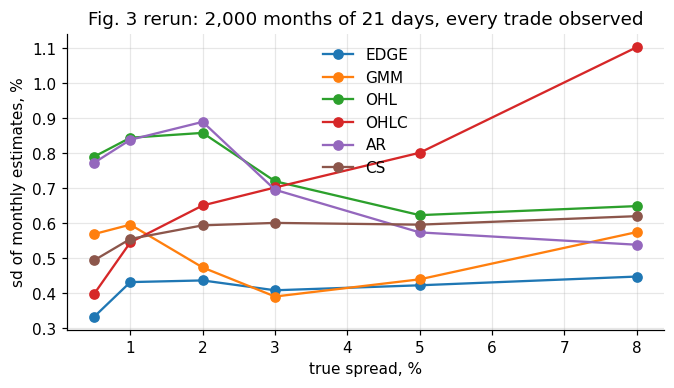

In [7]:
rows = []
for spread in (0.005, 0.01, 0.02, 0.03, 0.05, 0.08):
    bars = simulate(2000 * 21, SimConfig(prob=1.0, spread=spread), np.random.default_rng(int(1e4 * spread)))
    o, h, l, c = windows_with_lag(bars, 21)
    e = estimate(o, h, l, c, methods=('EDGE', 'GMM', 'OHL', 'OHLC', 'AR', 'CS'), sign=True)
    rows.append({'true spread, %': 100 * spread, **{m: 100 * np.nanstd(clip_zero(v), ddof=1) for m, v in e.items()}})
sd = pd.DataFrame(rows).set_index('true spread, %')
sd.plot(marker='o', figsize=(7, 3.5), ylabel='sd of monthly estimates, %', title='Fig. 3 rerun: 2,000 months of 21 days, every trade observed')
sd.round(3)

**Robustness.** The same simulation with one assumption relaxed at a time (true spread 1 %, 390 trades a day). Tick size and autocorrelated returns barely move EDGE; a buy share of 75 % is the one violation that biases it, and 3 % overnight jumps break CS. The tick variant restarts the price at 1 every month so that the tick stays at half the spread, as in the full run. The full grid, three trade rates and fifteen variants, is in `results/sim/robust.csv`.

,EDGE,AR,CS,ROLL
variant,,,,
paper setup,0.88,0.96,1.03,1.62
tick = 50 % of spread,0.94,0.94,1.04,1.54
"AR(1) returns, rho = 0.5",0.87,0.94,0.91,1.60
overnight vol 3 %,0.99,1.09,0.35,2.12
60 % buys,0.86,0.95,1.02,1.60
75 % buys,0.75,0.92,0.99,1.57


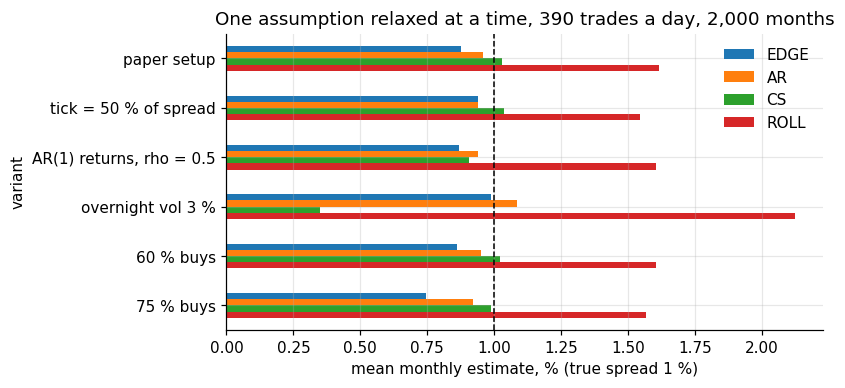

In [8]:
base = SimConfig(spread=0.01)
variants = {'paper setup': base, 'tick = 50 % of spread': replace(base, tick_size=0.005), 'AR(1) returns, rho = 0.5': replace(base, rho=0.5),
            'overnight vol 3 %': replace(base, overnight=0.03), '60 % buys': replace(base, buy_prob=0.6), '75 % buys': replace(base, buy_prob=0.75)}
def months(cfg, n_months=2000, n_obs=21, seed=7, restart=False):
    rng = np.random.default_rng(seed)
    if restart:
        bars = simulate(n_months * (n_obs + 1), replace(cfg, reset_period=n_obs + 1), rng).reshape(n_months, n_obs + 1, 4)
        return tuple(bars[:, :, j] for j in range(4))
    return windows_with_lag(simulate(n_months * n_obs, cfg, rng), n_obs)
rows = []
for name, cfg in variants.items():
    o, h, l, c = months(cfg, restart=cfg.tick_size > 0)
    e = estimate(o, h, l, c, methods=('EDGE', 'AR', 'CS', 'ROLL'), sign=True)
    rows.append({'variant': name, **{m: 100 * np.nanmean(clip_zero(v)) for m, v in e.items()}})
rb = pd.DataFrame(rows).set_index('variant')
ax = rb.plot.barh(figsize=(7, 3.5), xlabel='mean monthly estimate, % (true spread 1 %)', title='One assumption relaxed at a time, 390 trades a day, 2,000 months')
ax.axvline(1.0, color='black', linestyle='--', linewidth=1)
ax.invert_yaxis()
rb.round(2)

**Negative estimates.** Resetting a negative squared spread to zero, as the paper does in every table, inflates small spreads in short windows; the signed root-mean-square does not (true spread 0.5 %).

In [9]:
rows = []
for prob in (1.0, 0.01):
    for n_obs in (21, 252):
        n_months = 2000 if n_obs == 21 else 300
        o, h, l, c = windows_with_lag(simulate(n_months * n_obs, SimConfig(prob=prob, spread=0.005), np.random.default_rng(n_obs)), n_obs)
        s = estimate(o, h, l, c, methods=('EDGE',), sign=True)['EDGE']
        s = s[~np.isnan(s)]
        m2 = np.mean(np.sign(s) * s * s)
        rows.append({'trades per day': 390 * prob, 'window, days': n_obs, 'negative share, %': 100 * np.mean(s < 0),
                     'mean after reset to zero, %': 100 * np.mean(clip_zero(s)), 'signed RMS, %': 100 * np.sign(m2) * np.sqrt(abs(m2))})
pd.DataFrame(rows).set_index(['trades per day', 'window, days']).round(2)

negative share, %  mean after reset to zero, %  signed RMS, %
trades per day window, days                                                               
390.0          21                        25.60                         0.44           0.49
               252                        1.67                         0.49           0.51
3.9            21                        42.60                         0.73           0.61
               252                       36.67                         0.48           0.49

## 3. Real data

Monthly estimates from daily prices: ETHUSDT on Binance since 2017 and two Moscow Exchange stocks, liquid SBER and thin LSNG, since 2024. `data/sample/` holds extracts of what `scripts/download_binance_daily_api.py` and `scripts/download_moex_history.py` download; the notebook uses the full local data when it is present.

,trades/day,EDGE,AR,CS,ROLL
month,,,,,
2026-05-01,2386858,0.000,0.0,0.599,0.470
2026-06-01,4048668,0.008,0.0,0.000,0.000
2026-07-01,2264512,0.006,0.0,0.203,0.370
2026-08-01,2376101,0.000,0.0,0.360,0.000
2026-09-01,2512341,0.000,0.0,0.031,1.874
2026-10-01,2256074,0.000,0.0,0.000,0.000


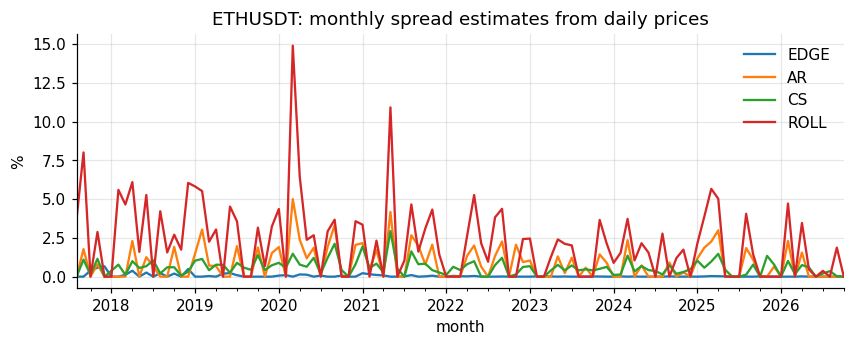

In [10]:
p = 'data/binance/daily/ETHUSDT.parquet'
df = pd.read_parquet(p) if os.path.exists(p) else pd.read_csv(sample('ETHUSDT_1d.csv'))
df['open_time'] = pd.to_datetime(df['open_time'], utc=True).dt.tz_convert(None)
out = []
for ym, g in df.groupby(df['open_time'].dt.to_period('M')):
    e = estimate(g['open'].values, g['high'].values, g['low'].values, g['close'].values, methods=('EDGE', 'AR', 'CS', 'ROLL'), sign=True)
    out.append({'month': ym.to_timestamp(), 'trades/day': int(g['n_trades'].mean()), **{k: 100 * clip_zero(v) for k, v in e.items()}})
eth = pd.DataFrame(out).set_index('month')
display(eth.tail(6).round(3))
eth[['EDGE', 'AR', 'CS', 'ROLL']].plot(figsize=(9, 3), ylabel='%', title='ETHUSDT: monthly spread estimates from daily prices');

,days,trades/day,"open or close at high/low, %",EDGE,AR,CS,ROLL
stock,,,,,,,
SBER,710,123089,3.521,0.387,0.0,0.077,0.412
LSNG,710,897,23.380,0.606,0.0,0.274,0.000


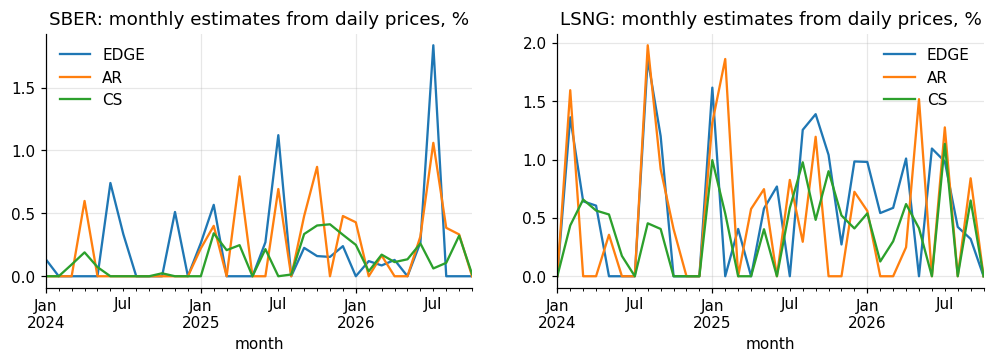

In [11]:
p = 'data/moex/daily_tqbr.parquet'
full = pd.read_parquet(p) if os.path.exists(p) else pd.read_csv(sample('moex_daily_SBER_LSNG.csv'), parse_dates=['TRADEDATE'])
rows = []
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
for ax, secid in zip(axes, ('SBER', 'LSNG')):
    g = full[(full['SECID'] == secid) & (full['NUMTRADES'] > 0) & (full['TRADEDATE'] >= '2024-01-01')].sort_values('TRADEDATE')
    e = estimate(g['OPEN'].values, g['HIGH'].values, g['LOW'].values, g['CLOSE'].values, methods=('EDGE', 'AR', 'CS', 'ROLL'), sign=True)
    at_extreme = (g['OPEN'] == g['HIGH']) | (g['OPEN'] == g['LOW']) | (g['CLOSE'] == g['HIGH']) | (g['CLOSE'] == g['LOW'])
    rows.append({'stock': secid, 'days': len(g), 'trades/day': int(g['NUMTRADES'].mean()), 'open or close at high/low, %': 100 * at_extreme.mean(), **{k: 100 * clip_zero(v) for k, v in e.items()}})
    monthly = []
    for ym, gm in g.groupby(g['TRADEDATE'].dt.to_period('M')):
        em = estimate(gm['OPEN'].values, gm['HIGH'].values, gm['LOW'].values, gm['CLOSE'].values, methods=('EDGE', 'AR', 'CS'), sign=True)
        monthly.append({'month': ym.to_timestamp(), **{k: 100 * clip_zero(v) for k, v in em.items()}})
    pd.DataFrame(monthly).set_index('month').plot(ax=ax, title=f'{secid}: monthly estimates from daily prices, %')
pd.DataFrame(rows).set_index('stock').round(3)

## 4. Fig. 8: crypto across frequencies

`scripts/compute_crypto_estimates.py` ran the estimators on 21 Binance pairs from daily, hourly and minute prices; `results/crypto/fig8_monthly_means.csv` holds the monthly cross-pair averages and `results/crypto/validation_vs_authors.csv` our minute-price estimates next to the 902 pair-months the authors released.

validation against the authors' released minute-price estimates: 902 pair-months, largest difference 9.9e-17


freq,1d,1h,1m
estimator,,,
EDGE,0.180,0.136,0.129
AR,0.907,0.214,0.083
CS,0.870,0.175,0.019


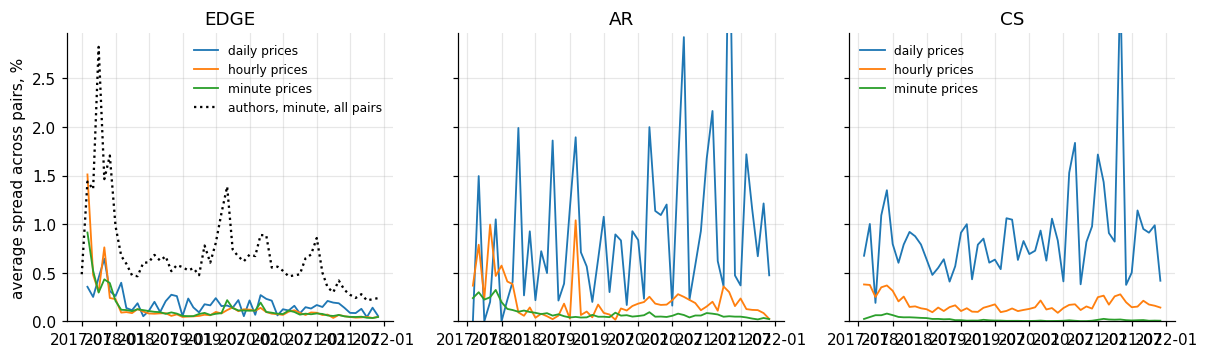

In [12]:
f8 = pd.read_csv('results/crypto/fig8_monthly_means.csv', parse_dates=['month'])
authors = pd.read_csv('results/crypto/fig8_authors_1m_means.csv', parse_dates=['month'])
period = f8[f8['month'] <= '2021-12-31']
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
for ax, m in zip(axes, ('EDGE', 'AR', 'CS')):
    for f, label in (('1d', 'daily'), ('1h', 'hourly'), ('1m', 'minute')):
        d = period[(period['estimator'] == m) & (period['freq'] == f)].sort_values('month')
        ax.plot(d['month'], 100 * d['mean_estimate'], label=f'{label} prices', linewidth=1.2)
    if m == 'EDGE':
        a = authors[authors['month'] <= '2021-12-31']
        ax.plot(a['month'], 100 * a['mean_estimate'], color='black', linestyle=':', label='authors, minute, all pairs')
    ax.set_title(m)
    ax.set_ylim(bottom=0)
axes[0].set_ylabel('average spread across pairs, %')
axes[0].legend(fontsize=8)
axes[2].legend(fontsize=8)
val = pd.read_csv('results/crypto/validation_vs_authors.csv')
print(f"validation against the authors' released minute-price estimates: {len(val)} pair-months, largest difference {val['abs_diff'].max():.1e}")
summary = period.groupby(['estimator', 'freq'])['mean_estimate'].mean().unstack('freq')[['1d', '1h', '1m']].loc[['EDGE', 'AR', 'CS']] * 100
summary.round(3)

## 5. The benchmark the paper lacks for crypto

Binance publishes every trade with the aggressor flag and every best bid/ask change for its futures (May 2023 to March 2024). `scripts/compute_crypto_benchmark.py` computed, for 30 symbols on 20 days, the effective spread of every trade matched to the quote in force, the authors' TAQ construction, and the estimators from bars of 1 s to 15 min built from the same trades. The per-day table is `results/crypto/benchmark_pair_day.csv`; the comparison is computed here.

600 pair-days, 30 symbols; mean effective spread 4.4 bp, mean time-weighted quoted spread 3.1 bp


estimator,EDGE,AR,CS,ROLL
bars,,,,
1s,82.5,73.2,53.4,76.1
10s,75.8,71.3,56.7,65.9
1m,71.3,49.9,47.4,38.6
5m,68.0,35.2,28.7,26.5
15m,57.0,19.1,25.1,7.9


,"Pearson, %","Spearman, %","zero estimates, %",mean estimate / mean effective
estimator,,,,
EDGE,95.57,82.55,27.67,0.79
AR,61.35,73.21,16.33,0.11
CS,21.54,53.35,55.67,0.00
ROLL,74.21,76.09,27.33,0.16


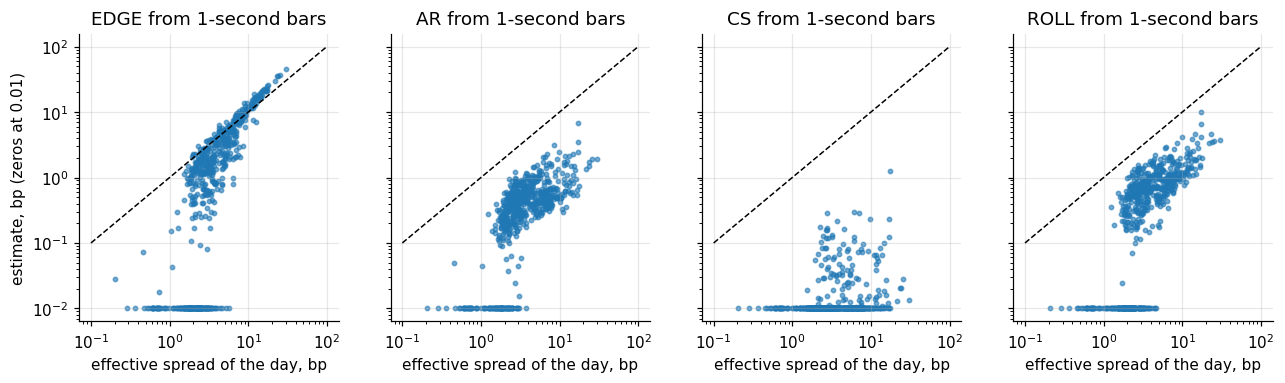

In [13]:
cb = pd.read_csv('results/crypto/benchmark_pair_day.csv')
print(f"{len(cb)} pair-days, {cb['symbol'].nunique()} symbols; mean effective spread {1e4 * cb['eff_mean'].mean():.1f} bp, mean time-weighted quoted spread {1e4 * cb['quoted_tw'].mean():.1f} bp")
rows = []
for f in ('1s', '10s', '1m', '5m', '15m'):
    for m in ('EDGE', 'AR', 'CS', 'ROLL'):
        d = cb[['eff_mean', f'{m}_{f}']].dropna()
        est = np.maximum(0, d[f'{m}_{f}'])
        rows.append({'bars': f, 'estimator': m, 'Pearson, %': 100 * np.corrcoef(d['eff_mean'], est)[0, 1], 'Spearman, %': 100 * d['eff_mean'].corr(est, method='spearman'),
                     'zero estimates, %': 100 * np.mean(est <= 0), 'mean estimate / mean effective': est.mean() / d['eff_mean'].mean()})
bench = pd.DataFrame(rows)
display(bench.pivot(index='bars', columns='estimator', values='Spearman, %').loc[['1s', '10s', '1m', '5m', '15m'], ['EDGE', 'AR', 'CS', 'ROLL']].round(1))
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4), sharex=True, sharey=True)
for ax, m in zip(axes, ('EDGE', 'AR', 'CS', 'ROLL')):
    d = cb[['eff_mean', f'{m}_1s']].dropna()
    ax.scatter(1e4 * d['eff_mean'], 1e4 * np.maximum(1e-6, d[f'{m}_1s']), s=8, alpha=0.6)
    ax.plot([0.1, 100], [0.1, 100], 'k--', linewidth=1)
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_title(f'{m} from 1-second bars')
    ax.set_xlabel('effective spread of the day, bp')
axes[0].set_ylabel('estimate, bp (zeros at 0.01)')
bench[bench['bars'] == '1s'].set_index('estimator').drop(columns='bars').round(2)

## 6. Moscow Exchange

`scripts/compute_moex_daily.py` ran the estimators on every share of the main board since 2013 (411 shares, delisted ones included, funds and ETFs excluded); `results/moex/spread_by_tier_month.csv` holds the monthly averages by liquidity tier and `results/moex/table4E_by_numtrades.csv` the Table 4E analogue.

small shares, EDGE: 4.22 % in 2014, 0.99 % over the last twelve months


,stock-months,median trades/day,P[o/c=h/l],EDGE mean,EDGE zero%,AR mean,AR zero%,CS mean,CS zero%,ROLL mean,ROLL zero%
Numtrd quintile,,,,,,,,,,,
1,3239,10,39.7,3.14,17,1.65,24,0.39,29,2.38,23
2,9495,38,26.7,2.27,17,1.45,26,0.56,20,2.06,27
3,8537,131,17.0,1.66,18,1.18,30,0.62,15,1.71,30
4,8225,960,8.6,0.84,25,0.69,42,0.46,18,1.14,39
5,7931,12418,4.4,0.44,38,0.42,51,0.28,27,0.93,43


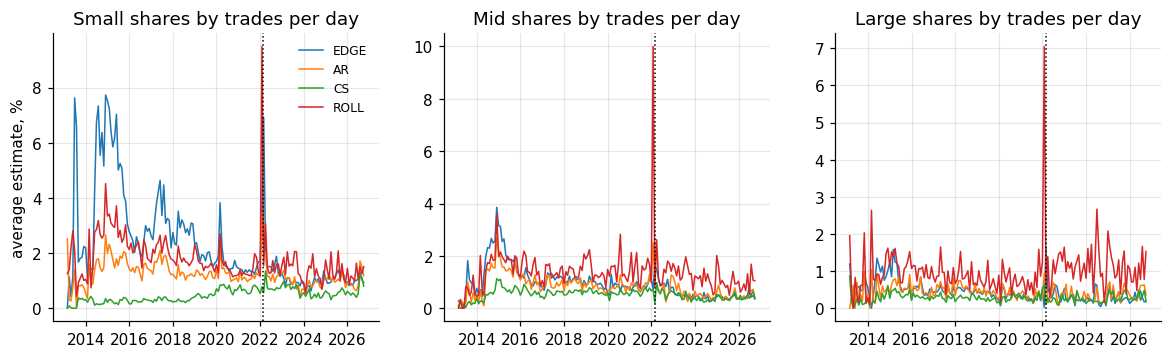

In [14]:
tier = pd.read_csv('results/moex/spread_by_tier_month.csv', parse_dates=['month'])
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, t in zip(axes, ('Small', 'Mid', 'Large')):
    for m in ('EDGE', 'AR', 'CS', 'ROLL'):
        d = tier[(tier['tier'] == t) & (tier['estimator'] == m)].sort_values('month')
        ax.plot(d['month'], 100 * d['mean_estimate'], label=m, linewidth=1)
    ax.axvline(pd.Timestamp('2022-02-25'), color='black', linestyle=':', linewidth=1)
    ax.set_title(f'{t} shares by trades per day')
axes[0].set_ylabel('average estimate, %')
axes[0].legend(fontsize=8)
small = tier[(tier['tier'] == 'Small') & (tier['estimator'] == 'EDGE')].set_index('month')['mean_estimate'] * 100
print(f"small shares, EDGE: {small['2014'].mean():.2f} % in 2014, {small.iloc[-12:].mean():.2f} % over the last twelve months")
t4 = pd.read_csv('results/moex/table4E_by_numtrades.csv', dtype=str).set_index('Numtrd quintile')
t4[['stock-months', 'median trades/day', 'P[o/c=h/l]', 'EDGE mean', 'EDGE zero%', 'AR mean', 'AR zero%', 'CS mean', 'CS zero%', 'ROLL mean', 'ROLL zero%']]

Our own quote feed: `scripts/collect_moex_quotes.py` polled the best bid and offer of every TQBR instrument every 5 seconds; `scripts/compute_moex_quoted_benchmark.py` turned that into a time-weighted quoted spread per share-day and ran the estimators on the 1- and 10-minute candles of the same day (`results/moex/quoted_benchmark_stock_day.csv`). The comparison, a cross-sectional test like the paper's Fig. 4, is computed here.

253 shares on 2026-10-12; the collector covered 50 % of the trading day; mean quoted spread 0.34 %


share-days  Pearson, %  Spearman, %  zero estimates, %  mean estimate / mean quoted
sample                                             estimator                                                                                     
1-minute candles, all shares                       EDGE              200       52.04        31.16              18.00                         0.79
                                                   AR                200       12.54        -4.84              14.00                         0.15
                                                   CS                200      -19.65       -41.44              43.50                         0.01
                                                   ROLL              200       20.03         7.49              12.00                         0.23
10-minute candles, all shares                      EDGE              218       65.86        54.81              14.22                         0.90
                                                   AR                218       36.48        37.50               9.63                         0.46
                                                   CS                218      -32.21       -43.52              19.27                         0.09
                                                   ROLL              218       25.93        27.21              11.47                         0.70
1-minute candles, shares with at least 400 trad... EDGE               97       93.71        92.64               1.03                         1.16
                                                   AR                 97       68.37        67.69               1.03                         0.61
                                                   CS                 97       30.06         4.44              22.68                         0.07
                                                   ROLL               97       75.10        74.98               3.09                         0.85

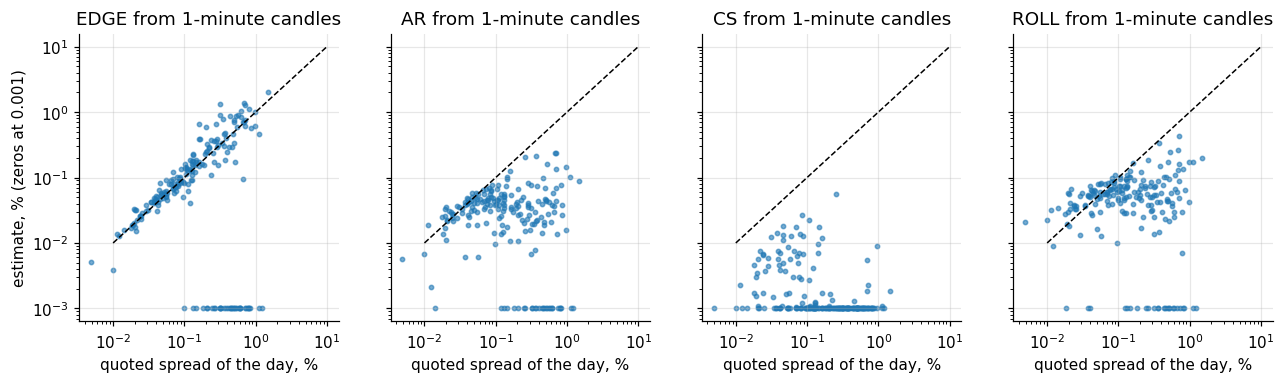

In [15]:
qb = pd.read_csv('results/moex/quoted_benchmark_stock_day.csv')
print(f"{qb['secid'].nunique()} shares on {qb['date'].iloc[0]}; the collector covered {100 * qb['observed_share'].iloc[0]:.0f} % of the trading day; mean quoted spread {100 * qb['quoted_spread'].mean():.2f} %")
def compare(d, f):
    rows = []
    for m in ('EDGE', 'AR', 'CS', 'ROLL'):
        est = np.maximum(0, d[f'{m}_{f}'])
        rows.append({'estimator': m, 'share-days': len(d), 'Pearson, %': 100 * np.corrcoef(d['quoted_spread'], est)[0, 1], 'Spearman, %': 100 * d['quoted_spread'].corr(est, method='spearman'),
                     'zero estimates, %': 100 * np.mean(est <= 0), 'mean estimate / mean quoted': est.mean() / d['quoted_spread'].mean()})
    return pd.DataFrame(rows).set_index('estimator')
def columns(f):
    return ['quoted_spread'] + [f'{m}_{f}' for m in ('EDGE', 'AR', 'CS', 'ROLL')]
tables = {'1-minute candles, all shares': compare(qb[columns('1m')].dropna(), '1m'),
          '10-minute candles, all shares': compare(qb[columns('10m')].dropna(), '10m'),
          '1-minute candles, shares with at least 400 traded minutes': compare(qb[qb['n_candles_1m'] >= 400][columns('1m')].dropna(), '1m')}
display(pd.concat(tables, names=['sample']).round(2))
d = qb[columns('1m')].dropna()
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4), sharex=True, sharey=True)
for ax, m in zip(axes, ('EDGE', 'AR', 'CS', 'ROLL')):
    ax.scatter(100 * d['quoted_spread'], 100 * np.maximum(1e-5, d[f'{m}_1m']), s=8, alpha=0.6)
    ax.plot([0.01, 10], [0.01, 10], 'k--', linewidth=1)
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_title(f'{m} from 1-minute candles')
    ax.set_xlabel('quoted spread of the day, %')
axes[0].set_ylabel('estimate, % (zeros at 0.001)');

## 7. Where the rest is

`reports/tables.md` has every table of the full runs and `reports/` the figures, all written by `scripts/make_figures.py` from `results/`; the data steps are listed in the README.